In [1]:
import os
import warnings
import pandas as pd
import logging

In [2]:
BASE_DIR = os.path.abspath("..")

DATA_DIR = os.path.join(BASE_DIR, "data")
OUTPUT_DIR = os.path.join(BASE_DIR, "outputs")
PLOT_DIR = os.path.join(OUTPUT_DIR, "plots")
REPORT_DIR = os.path.join(OUTPUT_DIR, "reports")
LOG_DIR = os.path.join(BASE_DIR, "logs")

for folder in [OUTPUT_DIR, PLOT_DIR, REPORT_DIR, LOG_DIR]:
    os.makedirs(folder, exist_ok=True)

print("Project directories are ready.")
print("Data directory:", DATA_DIR)

Project directories are ready.
Data directory: C:\Users\ijish\Desktop\Rossmann Sales Forecasting Project\data


## Loading The Datasets

### Training Dataset

In [3]:
train = pd.read_csv(
    os.path.join(DATA_DIR, "train.csv"),
    dtype={"StateHoliday": "string"},
    parse_dates=["Date"]
)

print(train.shape)
display(train.head())

(1017209, 9)


,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday
0,1,5,2015-07-31,5263,555,1,1,0,1
1,2,5,2015-07-31,6064,625,1,1,0,1
2,3,5,2015-07-31,8314,821,1,1,0,1
3,4,5,2015-07-31,13995,1498,1,1,0,1
4,5,5,2015-07-31,4822,559,1,1,0,1


### Dataset Overview & Feature Description
The training dataset contains historical daily sales records for individual stores. The train.csv dataset contains 1,017,209 records and 9 features. The training dataset is used to investigate historical customer behavior and sales patterns for training the machine learning model.

#### Feature Description:
+ Store: Unique identifier of the store.
+ DayOfWeek: Day of the week, where 1 = Monday and 7 = Sunday.
+ Date: Date on which sales were recorded.
+ Sales: Daily sales, which is the target for the later forecasting task.
+ Customers: Number of customers visited the store on that day.
+ Open: Whether the store was open, 1 = Open and 0 = Closed.
+ Promo: Whether a promotion was running on that day.
+ StateHoliday: State holiday indicator, indicating whether the day was affected by state holiday.
+ SchoolHoliday: School holiday indicator, indicating whether public schools were closed on that day.

### Test Dastset

In [4]:
test = pd.read_csv(
    os.path.join(DATA_DIR, "test.csv"),
    dtype={"StateHoliday": "string"},
    parse_dates=["Date"]
)

print(test.shape)
display(test.head())

(41088, 8)


,Id,Store,DayOfWeek,Date,Open,Promo,StateHoliday,SchoolHoliday
0,1,1,4,2015-09-17,1.0,1,0,0
1,2,3,4,2015-09-17,1.0,1,0,0
2,3,7,4,2015-09-17,1.0,1,0,0
3,4,8,4,2015-09-17,1.0,1,0,0
4,5,9,4,2015-09-17,1.0,1,0,0


### Dataset Overview & Feature Description
The test dataset contains store-date combinations records for which sales must eventually be predicted. It does not contain actual Sales or Customers values unlike train.csv dataset. The test.csv contains 41,088 records and 8 feature. This contains the same predictor information as train.csv except for Sales column, as sales values are needed to be predicted.

#### Feature Description:
+ Store: Unique identifier of the store.
+ DayOfWeek: Day of the week, where 1 = Monday and 7 = Sunday.
+ Date: Date for which sales need to be predicted.
+ Customers: Number of customers associated with the record, if available.
+ Open: Whether the store was open, 1 = Open and 0 = Closed.
+ Promo: Whether a promotion was running in a store.
+ StateHoliday: State holiday indicator, indicating whether the day was affected by state holiday.
+ SchoolHoliday: School holiday indicator, indicating whether public schools were closed on that day.


### Store Dataset

In [5]:
store = pd.read_csv(
    os.path.join(DATA_DIR, "store.csv")
)

print(store.shape)
display(store.head())

(1115, 10)


,Store,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
0,1,c,a,1270.0,9.0,2008.0,0,NaN,NaN,NaN
1,2,a,a,570.0,11.0,2007.0,1,13.0,2010.0,"Jan,Apr,Jul,Oct"
2,3,a,a,14130.0,12.0,2006.0,1,14.0,2011.0,"Jan,Apr,Jul,Oct"
3,4,c,c,620.0,9.0,2009.0,0,NaN,NaN,NaN
4,5,a,a,29910.0,4.0,2015.0,0,NaN,NaN,NaN


### Dataset Overview & Feature Description
The store.csv file contains information about individual stores. This gives information for 1,115 unique stores with 10 features. These features will help us investigate how store characteristics affect sales and customer behavior.

#### Feature Description:
+ Store:  Unique store identifier.
+ StoreType: Type of store: a, b, c, d.
+ Assortment: Level of product assortment, a = Basic, b = Extra, c = Extended.
+ CompetitionDistance: Distance to the nearest competitor store.
+ CompetitionOpenSinceMonth: Month in which the nearest competitor opened.
+ CompetitionOpenSinceYear: Year in which nearest the competitor opened.
+ Promo2: Whether the store participates in a continuing promotion.
+ Promo2SinceWeek: Week the continuing promotion began.
+ romo2SinceYear: Year the continuing promotion began.
+ PromoInterval: Months in which the continuing promotion is repeated.

### Sample Submission File

In [6]:
sample_submission = pd.read_csv(
    os.path.join(DATA_DIR, "sample_submission.csv")
)

print(sample_submission.shape)
display(sample_submission.head())

(41088, 2)


,Id,Sales
0,1,0
1,2,0
2,3,0
3,4,0
4,5,0


### File Overview
The sample_submission.csv file shows the expected format of the final sales prediction output. It contains 41,088 rows and 2 columns.

## Overall Data Overview

The project uses four csv files to prepare the data for model prediction. 
+ The train.csv contains historical observations and the target sales variable, useful for model training.
+ The test.csv contains observations for which predictions are required. It is used for model prediction.
+ The store.csv contains additional store level information and is combined with training and test datasets.
+ The sample_submission.csv file provide the required structure and format for the final submission file.

The store.csv file is joined with both the train.csv and test.csv dataset using the unique store identifier, to obtain the final training and test dataset. This integraton enhance the transactional data with store-level features, to allow the model to learn from both historical observations and store characteristics.

## Understand Structure of Each Data

In [7]:
datasets = {
    "Train": train,
    "Test": test,
    "Store": store,
    "Sample Submission": sample_submission
}

for name, df in datasets.items():

    print(f"\n{name} Dataset")
    print("-" * 50)

    print("Rows:", df.shape[0])
    print("Columns:", df.shape[1])
    print("Column names:", df.columns.tolist())


Train Dataset
--------------------------------------------------
Rows: 1017209
Columns: 9
Column names: ['Store', 'DayOfWeek', 'Date', 'Sales', 'Customers', 'Open', 'Promo', 'StateHoliday', 'SchoolHoliday']

Test Dataset
--------------------------------------------------
Rows: 41088
Columns: 8
Column names: ['Id', 'Store', 'DayOfWeek', 'Date', 'Open', 'Promo', 'StateHoliday', 'SchoolHoliday']

Store Dataset
--------------------------------------------------
Rows: 1115
Columns: 10
Column names: ['Store', 'StoreType', 'Assortment', 'CompetitionDistance', 'CompetitionOpenSinceMonth', 'CompetitionOpenSinceYear', 'Promo2', 'Promo2SinceWeek', 'Promo2SinceYear', 'PromoInterval']

Sample Submission Dataset
--------------------------------------------------
Rows: 41088
Columns: 2
Column names: ['Id', 'Sales']


In [8]:
print("TRAIN DATA TYPES")
display(train.dtypes.to_frame("Data Type"))

print("TEST DATA TYPES")
display(test.dtypes.to_frame("Data Type"))

print("STORE DATA TYPES")
display(store.dtypes.to_frame("Data Type"))

TRAIN DATA TYPES


,Data Type
Store,int64
DayOfWeek,int64
Date,datetime64[ns]
Sales,int64
Customers,int64
Open,int64
Promo,int64
StateHoliday,string[python]
SchoolHoliday,int64


TEST DATA TYPES


,Data Type
Id,int64
Store,int64
DayOfWeek,int64
Date,datetime64[ns]
Open,float64
Promo,int64
StateHoliday,string[python]
SchoolHoliday,int64


STORE DATA TYPES


,Data Type
Store,int64
StoreType,object
Assortment,object
CompetitionDistance,float64
CompetitionOpenSinceMonth,float64
CompetitionOpenSinceYear,float64
Promo2,int64
Promo2SinceWeek,float64
Promo2SinceYear,float64
PromoInterval,object


### Handling Missing Values

#### Missing Values in Store Dataset

In [9]:
store.describe()

,Store,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear
count,1115.00000,1112.000000,761.000000,761.000000,1115.000000,571.000000,571.000000
mean,558.00000,5404.901079,7.224704,2008.668857,0.512108,23.595447,2011.763573
std,322.01708,7663.174720,3.212348,6.195983,0.500078,14.141984,1.674935
min,1.00000,20.000000,1.000000,1900.000000,0.000000,1.000000,2009.000000
25%,279.50000,717.500000,4.000000,2006.000000,0.000000,13.000000,2011.000000
50%,558.00000,2325.000000,8.000000,2010.000000,1.000000,22.000000,2012.000000
75%,836.50000,6882.500000,10.000000,2013.000000,1.000000,37.000000,2013.000000
max,1115.00000,75860.000000,12.000000,2015.000000,1.000000,50.000000,2015.000000


In [10]:
store.duplicated().sum()

np.int64(0)

+ No duplicates record were found.

In [11]:
store.isnull().sum()

Store                          0
StoreType                      0
Assortment                     0
CompetitionDistance            3
CompetitionOpenSinceMonth    354
CompetitionOpenSinceYear     354
Promo2                         0
Promo2SinceWeek              544
Promo2SinceYear              544
PromoInterval                544
dtype: int64

#### Insight
+ CompetitionDistance has three missing values, while columns such as Store, StoreType, Assortment and Promo2 has 0 missing values.
+ CompetiotionOpenSinceMonth and CompetitionOpenSinceYear have 354 missing values.
+ Promo2SinceWeek, Promo2SinceYear and PromoInterval have 544 missing values.

In [12]:
store_missing_details = store[
    store.isnull().any(axis=1)
].copy()

display(store_missing_details.head(20))

print("Rows containing missing values:", len(store_missing_details))

,Store,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
0,1,c,a,1270.0,9.0,2008.0,0,NaN,NaN,NaN
3,4,c,c,620.0,9.0,2009.0,0,NaN,NaN,NaN
4,5,a,a,29910.0,4.0,2015.0,0,NaN,NaN,NaN
5,6,a,a,310.0,12.0,2013.0,0,NaN,NaN,NaN
6,7,a,c,24000.0,4.0,2013.0,0,NaN,NaN,NaN
7,8,a,a,7520.0,10.0,2014.0,0,NaN,NaN,NaN
8,9,a,c,2030.0,8.0,2000.0,0,NaN,NaN,NaN
9,10,a,a,3160.0,9.0,2009.0,0,NaN,NaN,NaN
11,12,a,c,1070.0,NaN,NaN,1,13.0,2010.0,"Jan,Apr,Jul,Oct"
12,13,d,a,310.0,NaN,NaN,1,45.0,2009.0,"Feb,May,Aug,Nov"


Rows containing missing values: 750


In [13]:
store['CompetitionDistance'] = (store['CompetitionDistance'].fillna(store['CompetitionDistance'].median()))

#### Justification:
+ The CompetitionDistance column contains 3 missing values and as this represents the distance to the nearest competitor store, median was selescted as imputation method.

In [14]:
missing_promo = store[store['Promo2'] == 0]
missing = pd.DataFrame([missing_promo['Promo2'], missing_promo['Promo2SinceWeek'], missing_promo['Promo2SinceYear'], missing_promo['PromoInterval']])
missing.T

,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
0,0.0,NaN,NaN,NaN
3,0.0,NaN,NaN,NaN
4,0.0,NaN,NaN,NaN
5,0.0,NaN,NaN,NaN
6,0.0,NaN,NaN,NaN
...,...,...,...,...
1107,0.0,NaN,NaN,NaN
1109,0.0,NaN,NaN,NaN
1111,0.0,NaN,NaN,NaN
1112,0.0,NaN,NaN,NaN


In [15]:
mask = store['Promo2'] == 0
store.loc[mask, 'Promo2SinceWeek'] = 0
store.loc[mask, 'Promo2SinceYear'] = 0
store.loc[mask, 'PromoInterval'] = 'None'
    

#### Justification:
+ Promo2SinceWeek, Promo2SinceYear and PromoInterval are promotional features containing information about continuous promotional campaigns. Missing promo2 related values are treated according to campaign participation, to preserve non participatinng stores and incomplete promotional records.
+ Missing values of Promo2SinceWeek and Promo2SinceYear are treated as 0 for stores where Promo2 = 0, since these stores do not participate in the campaign.
+ Missing PromoInterval values are replaced with None for stores where Promo2 = 0.

In [16]:
store[
    store["CompetitionOpenSinceMonth"].isnull() |
    store["CompetitionOpenSinceYear"].isnull()
].shape

(354, 10)

In [18]:
# Create an indicator for missing competition opening information
store["CompetitionOpenDateMissing"] = (
    store["CompetitionOpenSinceMonth"].isnull() |
    store["CompetitionOpenSinceYear"].isnull()
).astype(int)

# Fill missing values
store["CompetitionOpenSinceMonth"] = (
    store["CompetitionOpenSinceMonth"].fillna(0)
)

store["CompetitionOpenSinceYear"] = (
    store["CompetitionOpenSinceYear"].fillna(0)
)

#### Justification:
+ The columns CompetitionOpenSinceMonth and CompetitionOpenSinceYear contain 354 missing values each. These columns represent the month and year when a competitor opened near a particular store.
+ Missing values in CompetitionOpenSinceMonth and CompetitionOpenSinceYear were handled by creating a new indicator column, CompetitionOpenDateMissing. Missing values were then replaced with 0 to retain all store records. The indicator column preserves information about missing competition opening dates, allowing the model to distinguish unknown dates from available information.

In [19]:
store.isnull().sum().sum()

np.int64(0)

#### Missing Values in Train & Test Dataset

In [21]:
train_missing = train.isnull().sum()
train_missing = train_missing[train_missing>0]

print("Missing values in Train dataset:")
print(train_missing)


test_missing = test.isnull().sum()
test_missing = test_missing[test_missing > 0]

print("Missing values in Test dataset:")
print(test_missing)

Missing values in Train dataset:
Series([], dtype: int64)
Missing values in Test dataset:
Open    11
dtype: int64


+ The training dataset has no missing values and is complete, while the test dataset has 11 missing values in the Open column and  requires targeted treatment.

In [22]:
# Display records where Open is missing
test[test["Open"].isnull()]

,Id,Store,DayOfWeek,Date,Open,Promo,StateHoliday,SchoolHoliday
479,480,622,4,2015-09-17,NaN,1,0,0
1335,1336,622,3,2015-09-16,NaN,1,0,0
2191,2192,622,2,2015-09-15,NaN,1,0,0
3047,3048,622,1,2015-09-14,NaN,1,0,0
4759,4760,622,6,2015-09-12,NaN,0,0,0
5615,5616,622,5,2015-09-11,NaN,0,0,0
6471,6472,622,4,2015-09-10,NaN,0,0,0
7327,7328,622,3,2015-09-09,NaN,0,0,0
8183,8184,622,2,2015-09-08,NaN,0,0,0
9039,9040,622,1,2015-09-07,NaN,0,0,0


In [23]:
test["Open"] = test["Open"].fillna(1)

In [24]:
test["Open"].isnull().sum()

np.int64(0)

#### Justification:
+ The Open column in the test dataset contained 11 missing values. This column indicates whether a store was open or closed on a particular day.
+ The 11 missing values were replaced with 1, assuming that the stores were open on those days. The missing values were handled without removing any records from the test dataset. This ensures that all test observations are retained for further analysis and sales prediction.

### Outlier Analysis

#### For Store Dataset

In [25]:
# Check numerical columns
store.select_dtypes(include=["int64", "float64"]).columns

Index(['Store', 'CompetitionDistance', 'CompetitionOpenSinceMonth',
       'CompetitionOpenSinceYear', 'Promo2', 'Promo2SinceWeek',
       'Promo2SinceYear', 'CompetitionOpenDateMissing'],
      dtype='object')

In [26]:
Q1 = store["CompetitionDistance"].quantile(0.25)
Q3 = store["CompetitionDistance"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = store[
    (store["CompetitionDistance"] < lower_bound) |
    (store["CompetitionDistance"] > upper_bound)
]

print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)
print("Outlier Count:", len(outliers))

print(
    "Outlier Percentage:",
    round((len(outliers) / len(store)) * 100, 2), "%"
)

Lower Bound: -8512.5
Upper Bound: 16107.5
Outlier Count: 108
Outlier Percentage: 9.69 %


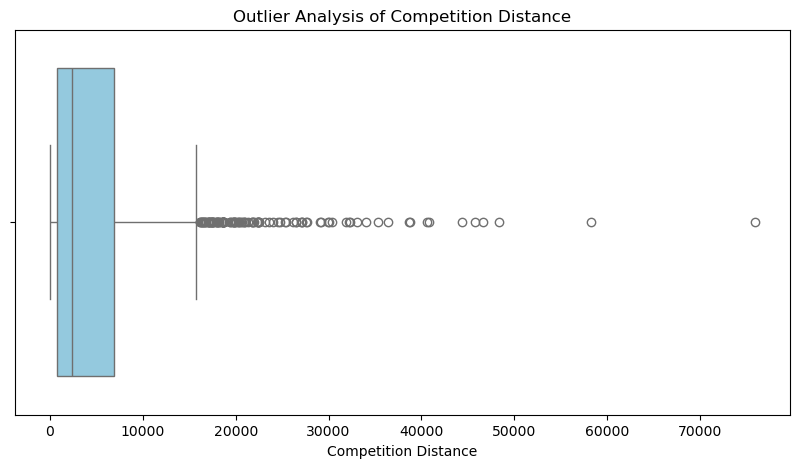

In [27]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))

sns.boxplot(
    x=store["CompetitionDistance"],
    color="skyblue"
)

plt.title("Outlier Analysis of Competition Distance")
plt.xlabel("Competition Distance")

plt.show()

#### Insight
+ For store dataset outlier analysis is performed only for CompetitionDistance column because competition distance is a continuous numerical variable, whereas the other columns represent months, years, or weeks. Applying IQR to those date-related columns may produce misleading results.
+ The IQR method identified 108 outliers in the CompetitionDistance column.
+ These outliers represent stores having unusually high competition distances compared to the majority of stores.
+ The presence of these values indicates that some stores have competitors located significantly farther away.
+ Such values may reflect genuine business conditions rather than incorrect data.
+ Higher competition distance may indicate lower direct competition nearby, although it does not necessarily guarantee higher sales.

#### Treatment

In [28]:
Q1 = store["CompetitionDistance"].quantile(0.25)
Q3 = store["CompetitionDistance"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)

Lower Bound: -8512.5
Upper Bound: 16107.5


In [29]:
# Create a copy of the original column
store["CompetitionDistance_Original"] = store["CompetitionDistance"]

# Apply IQR capping
store["CompetitionDistance"] = store["CompetitionDistance"].clip(
    lower=lower_bound,
    upper=upper_bound
)

In [30]:
# Recalculate outliers after capping
outliers_after = store[
    (store["CompetitionDistance"] < lower_bound) |
    (store["CompetitionDistance"] > upper_bound)
]

print("Outliers Before Capping:", len(outliers))
print("Outliers After Capping:", len(outliers_after))

Outliers Before Capping: 108
Outliers After Capping: 0


#### Justification
+ The IQR capping method was applied to handle extreme values. Values exceeding the calculated lower and upper bounds were replaced with their respective boundary values.
+ Capping reduced the influence of extreme observations while preserving all records in the dataset. No rows were removed during this process. The capped CompetitionDistance feature was retained for further analysis and machine learning preprocessing.

#### Outlier Analysis For Train Dataset

In [36]:
print("Train numerical columns:")
print(train.select_dtypes(include=["int64", "float64"]).columns)

Train numerical columns:
Index(['Store', 'DayOfWeek', 'Sales', 'Customers', 'Open', 'Promo',
       'SchoolHoliday'],
      dtype='object')


In [32]:
train[["Sales", "Customers"]].describe()

,Sales,Customers
count,1.017209e+06,1.017209e+06
mean,5.773819e+03,6.331459e+02
std,3.849926e+03,4.644117e+02
min,0.000000e+00,0.000000e+00
25%,3.727000e+03,4.050000e+02
50%,5.744000e+03,6.090000e+02
75%,7.856000e+03,8.370000e+02
max,4.155100e+04,7.388000e+03


In [34]:
numerical_cols = ["Sales", "Customers"]

for col in numerical_cols:

    Q1 = train[col].quantile(0.25)
    Q3 = train[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = train[
        (train[col] < lower_bound) |
        (train[col] > upper_bound)
    ]

    print(f"\nColumn: {col}")
    print("Lower Bound:", lower_bound)
    print("Upper Bound:", upper_bound)
    print("Outlier Count:", len(outliers))
    print(
        "Outlier Percentage:",
        round(len(outliers) / len(train) * 100, 2), "%"
    )


Column: Sales
Lower Bound: -2466.5
Upper Bound: 14049.5
Outlier Count: 26694
Outlier Percentage: 2.62 %

Column: Customers
Lower Bound: -243.0
Upper Bound: 1485.0
Outlier Count: 38095
Outlier Percentage: 3.75 %


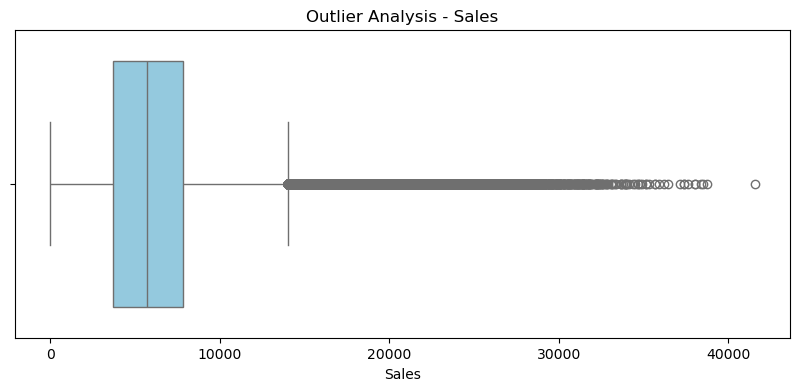

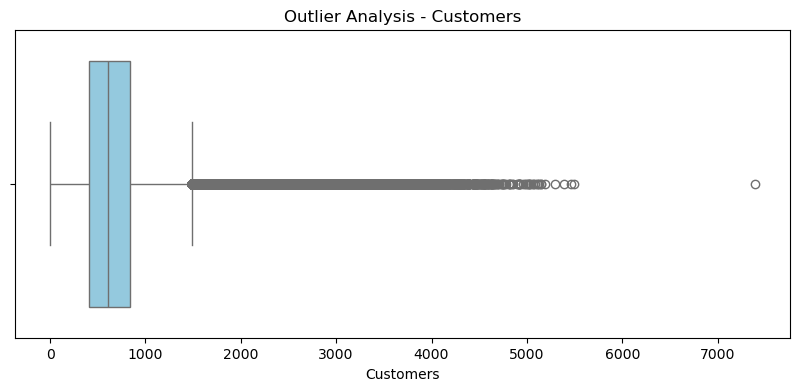

In [35]:
import matplotlib.pyplot as plt
import seaborn as sns

for col in ["Sales", "Customers"]:

    plt.figure(figsize=(10, 4))

    sns.boxplot(
        x=train[col],
        color="skyblue"
    )

    plt.title(f"Outlier Analysis - {col}")
    plt.xlabel(col)

    plt.show()

In [37]:
# Compare sales during promotional and non-promotional periods

train.groupby("Promo")["Sales"].describe()

,count,mean,std,min,25%,50%,75%,max
Promo,,,,,,,,
0,629129.0,4406.050805,3442.450020,0.0,0.0,4622.0,6367.0,41551.0
1,388080.0,7991.152046,3419.025495,0.0,5922.0,7553.0,9603.0,38722.0


In [38]:
train.groupby("Promo")["Customers"].describe()

,count,mean,std,min,25%,50%,75%,max
Promo,,,,,,,,
0,629129.0,517.823542,452.881419,0.0,0.0,512.0,726.0,5387.0
1,388080.0,820.098815,419.897191,0.0,581.0,747.0,972.0,7388.0


In [39]:
train.groupby("StateHoliday")["Sales"].mean()

StateHoliday
0    5947.483893
a     290.735686
b     214.311510
c     168.733171
Name: Sales, dtype: float64

#### Insights
-  IQR outlier analysis is applied only to Sales and Customers column as other numerical features such as Store, Open, Promo, SchoolHoliday are identifier or binary indicator, thus these features are exclude from IQR analysis.
- IQR method identified 26,694 outliers (2.62%) in the Sales column and 38,095 outliers (3.75%) in the Customers column.
- The presence of high sales values indicates variations in store sales performance and may be influenced by promotions, holidays, and customer demand.
- Higher customer counts may represent stores experiencing greater footfall during certain periods.
- The calculated lower bounds for both features were negative, which are not practically meaningful because sales and customer counts cannot be negative.

#### Treatment:

The identified outliers were retained because they may represent genuine business activity rather than incorrect observations. Removing or capping these values could result in the loss of important information required for sales forecasting.

#### Conclusion:

No outlier removal or capping was performed on Sales and Customers. The original observations were preserved for further exploratory data analysis and model development.

## Merge Training Data with Store Data

In [42]:
train_merged = train.merge(
    store,
    on="Store",
    how="left",
    validate="many_to_one"
)

print("Merged training shape:", train_merged.shape)
display(train_merged.head())

Merged training shape: (1017209, 20)


,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval,CompetitionOpenDateMissing,CompetitionDistance_Original
0,1,5,2015-07-31,5263,555,1,1,0,1,c,a,1270.0,9.0,2008.0,0,0.0,0.0,None,0,1270.0
1,2,5,2015-07-31,6064,625,1,1,0,1,a,a,570.0,11.0,2007.0,1,13.0,2010.0,"Jan,Apr,Jul,Oct",0,570.0
2,3,5,2015-07-31,8314,821,1,1,0,1,a,a,14130.0,12.0,2006.0,1,14.0,2011.0,"Jan,Apr,Jul,Oct",0,14130.0
3,4,5,2015-07-31,13995,1498,1,1,0,1,c,c,620.0,9.0,2009.0,0,0.0,0.0,None,0,620.0
4,5,5,2015-07-31,4822,559,1,1,0,1,a,a,16107.5,4.0,2015.0,0,0.0,0.0,None,0,29910.0


## Merge Test Data with Store Data

In [44]:
test_merged = test.merge(
    store,
    on="Store",
    how="left",
    validate="many_to_one"
)

print("Merged test shape:", test_merged.shape)

display(test_merged.head())

Merged test shape: (41088, 19)


,Id,Store,DayOfWeek,Date,Open,Promo,StateHoliday,SchoolHoliday,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval,CompetitionOpenDateMissing,CompetitionDistance_Original
0,1,1,4,2015-09-17,1.0,1,0,0,c,a,1270.0,9.0,2008.0,0,0.0,0.0,None,0,1270.0
1,2,3,4,2015-09-17,1.0,1,0,0,a,a,14130.0,12.0,2006.0,1,14.0,2011.0,"Jan,Apr,Jul,Oct",0,14130.0
2,3,7,4,2015-09-17,1.0,1,0,0,a,c,16107.5,4.0,2013.0,0,0.0,0.0,None,0,24000.0
3,4,8,4,2015-09-17,1.0,1,0,0,a,a,7520.0,10.0,2014.0,0,0.0,0.0,None,0,7520.0
4,5,9,4,2015-09-17,1.0,1,0,0,a,c,2030.0,8.0,2000.0,0,0.0,0.0,None,0,2030.0


#### Merged Dataset Analysis
+ The training and test datasets were merged with the store dataset using the Store column. This integration enriched both datasets with additional store-level information, including store type, assortment, competition distance, and promotional details.
+ The merged_train dataset contains 1,017,209 rows and 21 columns.
+ The merged_test dataset contains 41,088 rows and 19 columns
+ The merged training dataset provides a comprehensive view of daily sales and customer activity along with store characteristics. The merged test dataset contains corresponding store information required for future sales predictions.
+ This integrated dataset will be used for further exploratory data analysis, feature engineering, preprocessing, and machine learning model development.

In [46]:
train_merged.to_csv(
    os.path.join(OUTPUT_DIR, "train_merged.csv"),
    index=False
)

test_merged.to_csv(
    os.path.join(OUTPUT_DIR, "test_merged.csv"),
    index=False
)

print("Merged datasets saved successfully!")

Merged datasets saved successfully!
